In [1]:
# General libraries
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import numpy as np
import pandas as pd
from scipy.stats import kstest

# JAX
import jax
import jax.numpy as jnp

# Module functions
import ximinf.cosmo_helper as ch
import ximinf.data_helper as dh
import ximinf.nn_inference as nninf
import ximinf.nn_io as nnio
import ximinf.nn_test as nnte
import ximinf.nn_train as nntr
import ximinf.plots as plt_tools
plt_tools.apply_default_settings()

from_nn_sim = False

# Cosmology
from cosmologix import fitter

cosmo = ch.get_canonical("PlanckBAO18")
cosmologix_cosmo = ch.to_cosmologix(cosmo)

fiducial_cosmo = cosmologix_cosmo

The compilation cache as grown to 2.12 GB.Caching is disabled for now.Clear the cache using `cosmologix clear-cache -j` to re-enable.Or directly from python: tools.clear_cache(jit=True)


In [2]:
from source import nn_path
import re

match = re.search(r"sim_(\d+)", nn_path)
if match:
    sim_idx = match.group(1)

In [3]:
# Path to the new HDF5 file
# sim_idx = "0024"
sim_path = f"../data/SIM/sim_{sim_idx}"

print(f'IMPORTING PRESETS FROM SIM IDX {sim_idx}')
sim_config_temp = dh.load_module_from_run(sim_path, module_filename="sim_config.py")
SIMULATION_MODEL = sim_config_temp.SIMULATION_MODEL
noise_model = sim_config_temp.noise_model
true_params = sim_config_temp.params
columns = sim_config_temp.columns
z_max = sim_config_temp.z_max
N_test = sim_config_temp.N_test
M = sim_config_temp.M
survey_name = sim_config_temp.survey_name
ranges = sim_config_temp.ranges

IMPORTING PRESETS FROM SIM IDX 0024


In [4]:
num_threads = os.cpu_count()
print(f"Number of threads: {num_threads}")

Number of threads: 48


## Load data

In [5]:
# Parameters
global_param_names = ['mabs', 'beta', 'alpha'] #, 'gamma'

print(f"Parameters : {global_param_names}")

Parameters : ['mabs', 'beta', 'alpha']


In [6]:
# Load the data
params, data_dict, priors = dh.load_simulation(sim_path, file_name="simulations_test_reference.h5") #dh.

N_test=200

for key in params.keys():
    params[key] = params[key][0:N_test]

for key in data_dict.keys():
    data_dict[key] = data_dict[key][0:N_test]

# # Only update 'mabs' if it exists in params
if 'mabs' in true_params:
    params['mabs'] =  params['mabs'] + 19.3
    true_params['mabs'] =  true_params['mabs'] + 19.3

In [7]:
data_dict["magobs"][0][0]

np.float32(17.54646)

In [8]:
params['mabs'][0]

np.float32(0.0)

# Maximum Likelihood Estimation

In [9]:
class DiagSNIaStandardisation:
    """SN Ia standardisation block with latent x1 and c (duck-typed likelihood).

    Provides what cosmologix.fitter.fit / LikelihoodSum expect:
    `weighted_residuals(params)` and `initial_guess(params)`.
    """

    def __init__(self, z_cmb, magobs, magobs_err, x1, x1_err, c, c_err,
                 sigma_int=0.1, coefs=None):
        self.z_cmb = jnp.atleast_1d(z_cmb)
        self.magobs = jnp.atleast_1d(magobs)
        self.magerr = jnp.atleast_1d(magobs_err)
        self.x1 = jnp.atleast_1d(x1)
        self.x1_err = jnp.atleast_1d(x1_err)
        self.c = jnp.atleast_1d(c)
        self.c_err = jnp.atleast_1d(c_err)
        self.sigma_int = sigma_int  # fixed intrinsic scatter (not fitted)
        self.coefs = {k: jnp.atleast_1d(v) for k, v in (coefs or {}).items()}

    def model(self, params):
        return (
            params["M"]
            + params["alpha"] * params["x1"]
            + params["beta"] * params["c"]
            # + params["gamma"] * self.coefs["p"]
        )

    def weighted_residuals(self, params):
        sigma = jnp.sqrt(self.magerr**2 + self.sigma_int**2)
        r_m = (self.magobs - self.model(params)) / sigma
        # latent-variable constraints
        r_x1 = (params["x1"] - self.x1) / self.x1_err
        r_c = (params["c"] - self.c) / self.c_err
        return jnp.hstack([r_m, r_x1, r_c])

    def negative_log_likelihood(self, params):
        """chi2 helper (not used by Gauss-Newton)."""
        return jnp.sum(self.weighted_residuals(params) ** 2)

    def initial_guess(self, params):
        return dict(
            params,
            M=0.0,
            alpha=-0.16,
            beta=3.0,
            # gamma=0.14,
            x1=jnp.array(self.x1),
            c=jnp.array(self.c),
        )

In [10]:
key = jax.random.PRNGKey(42)

## Pre-process samples

In [11]:
data_dict_mle, mask = dh.remove_cosmology(data_dict, cosmo, package="astropy", disable_x64_after=False) #dh.

list_of_dfs = [
    pd.DataFrame({
        k: np.asarray(v[i])[mask[i]]
        for k, v in data_dict_mle.items()
    })
    for i in range(N_test)
]

In [12]:
list_of_dfs[0][-5:-1]

,c,c_err,magobs,magobs_err,x1,x1_err,z
995,0.342671,0.027254,1.069548,0.030337,-1.456073,0.093027,0.05765
996,-0.110854,0.030597,-0.202267,0.032240,-0.444689,0.096192,0.05795
997,-0.204498,0.027822,-0.779057,0.029642,1.987661,0.104043,0.02385
998,-0.239682,0.030450,-0.425261,0.031096,-1.442855,0.098053,0.05085


# Run the complete TARP

In [13]:
[true_params[p] for p in global_param_names]

[0.0, 3.05, -0.161]

In [14]:
# params_of_interest = ["alpha", "beta", "mabs", "gamma"]
true_thetas = np.column_stack([params[p] for p in global_param_names])
# true_thetas = np.tile(np.array([true_params[p] for p in global_param_names]), (N_total, 1))
prior_low  = np.array([float(ranges[p][0]) for p in global_param_names])
prior_high = np.array([float(ranges[p][1]) for p in global_param_names])

In [15]:
def build_likelihood_cosmologix(df):
    coefs = {
        "x1": df["x1"].to_numpy(),
        "c": df["c"].to_numpy(),
        # "p": df["isup"].to_numpy(),
    }

    return DiagSNIaStandardisation(
        z_cmb=df["z"].to_numpy(),
        magobs=df["magobs"].to_numpy(),
        magobs_err=df["magobs_err"].to_numpy(),
        x1=df["x1"].to_numpy(),
        x1_err=df["x1_err"].to_numpy(),
        c=df["c"].to_numpy(),
        c_err=df["c_err"].to_numpy(),
        sigma_int=true_params["sigma_int"],
        coefs=coefs,
    )

In [16]:
param_names = list(true_params.keys())

mu_list, cov_list = nnte.fit_cosmologix_datasets(
    list_of_dfs=list_of_dfs,
    fitter=fitter,
    fiducial_cosmo=fiducial_cosmo,
    param_names=param_names,
    params_of_interest=global_param_names,
    build_likelihood=build_likelihood_cosmologix,
)

Iteration 100/100

# Simulation based inference

In [17]:
device, backend, cpu, gpu = nntr.setup_jax_device()

gpu


In [18]:
from source import nn_path
nn_config_temp = dh.load_module_from_run(nn_path, module_filename="nn_config.py")

DeepSetClassifier = nn_config_temp.DeepSetClassifier

In [19]:
models_per_group, models_config = nnio.load_autoregressive_nn(nn_path, DeepSetClassifier)

In [20]:
priors = models_config["shared"]["priors"]
select_columns = models_config["shared"]["columns"]
data_stats = models_config["shared"]["data_stats"]

In [21]:
priors

{'alpha': {'range': array([-0.17882457, -0.14317542], dtype=float32),
  'type': 'uniform'},
 'beta': {'range': array([2.8717544, 3.2282457], dtype=float32),
  'type': 'uniform'},
 'mabs': {'range': array([-0.03087425,  0.03087234], dtype=float32),
  'type': 'uniform'}}

In [22]:
jax.config.update("jax_enable_x64", True)
data_dict_nre, mask = dh.remove_cosmology(data_dict, cosmologix_cosmo, package="cosmologix", disable_x64_after=True) #dh.
data_norm, M_norm = dh.normalize_data(data_dict_nre, select_columns, mask, data_stats)
data_concat = dh.build_data_concat(data_norm, select_columns, N_test, M)
del data_norm
inputs_infer = dh.build_inputs_infer(data_concat, mask, M_norm, N_test, M)
del data_concat

In [23]:
nnte.set_eval(models_per_group)

global_param_names = models_config['shared']['global_param_names']
print(f"Parameters : {global_param_names}")

param_groups = models_config['shared']['param_groups']

Parameters : ['mabs', 'beta', 'alpha']


In [24]:
param_stats = models_config['shared']['param_stats']

normalized_priors = {}

for name, prior in priors.items():
    mu = param_stats[name]['mu']
    sigma = param_stats[name]['sigma']

    norm_range = (prior['range'] - mu) / sigma
        
    normalized_priors[name] = {
        'range': norm_range,
        'type': prior['type']  # type stays unchanged
    }

# The theta dict must be the true values for the TARP to be valid
theta_dict = params

# theta_array = jnp.array(
#     [theta_dict[name] for name in global_param_names]
# )

theta_normed_dict = {
    name: (
        theta_dict[name] - param_stats[name]["mu"]
    ) / param_stats[name]["sigma"]
    for name in global_param_names
}

theta_normed = jnp.array(
    [theta_normed_dict[name] for name in global_param_names]
)

In [25]:
theta_star_list = theta_normed.T

group_names_list = []
for g in param_groups:
    if isinstance(g, str):
        group_names_list.append([g])  # wrap single parameter in a list
    else:
        group_names_list.append(g)  
        
visible_indices, group_indices = nninf.preprocess_groups(param_groups, global_param_names)

# MLE

In [26]:
# one source of truth for names/bounds/truth, physical units
names = ['mabs', 'beta', 'alpha']
true_thetas = nnte.stack_thetas(params, names) #nnte.
prior_low, prior_high = nnte.prior_bounds( #nnte.
    {p: {"range": ranges[p]} for p in names}, names)

# same reference points for both methods -> paired comparison
theta_ref = nnte.sample_reference_points(1234, prior_low, prior_high, N_test) #nnte.

# cosmologix (unchanged up to the samples)
n_points = 2000
post_cosmo = nnte.sample_from_gaussians(mu_list, cov_list, n_points) #nnte.

# identical call for both
alphas, ecp_c, f_c = nnte.run_tarp_from_samples(post_cosmo, true_thetas, prior_low, prior_high, theta_ref=theta_ref) #nnte.

## Local TARP

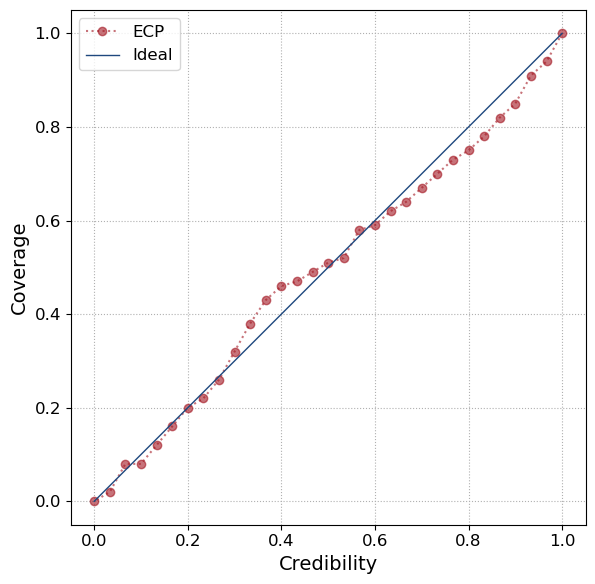

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Credibility', ylabel='Coverage'>)

In [27]:
%matplotlib inline
plt_tools.plot_ecp(alphas, ecp_c, sim_path, file_name="tarp_mle") 

In [28]:
stat, p = kstest(f_c, "uniform")
print(f"MLE p-value : {100*p:.1f} %")

MLE p-value : 72.6 %


## Pull

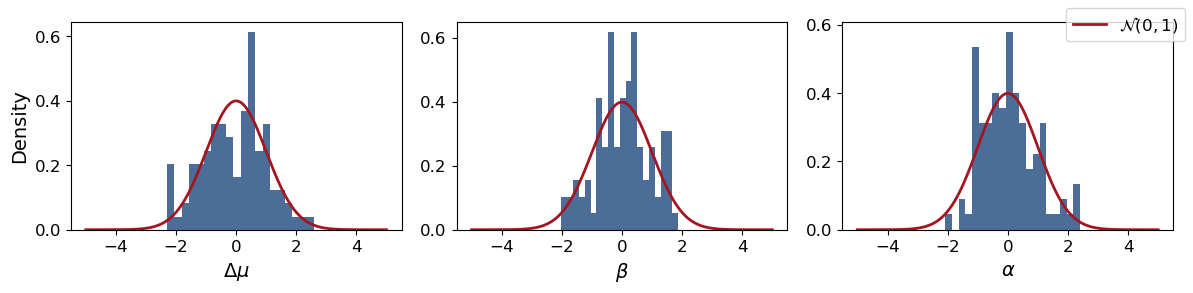

In [29]:
plt_tools.plot_pulls(mu_list, true_thetas, cov_list, global_param_names, plt_tools.param_labels, sim_path, file_name="systematics_mle")

# NRE

In [30]:
# NN
jax.block_until_ready(post_cosmo)
print("Compute posteriors from NN..")
post_nn, key = nnte.sample_nn_posteriors( #nnte.
    models_per_group, inputs_infer, theta_normed.T, normalized_priors, names,
    visible_indices, group_indices, group_names_list, param_stats,
    n_warmup=200, n_samples=n_points, rng_key=key)
print(".. done")

_, ecp_n, f_n = nnte.run_tarp_from_samples(post_nn,    true_thetas, prior_low, prior_high, theta_ref=theta_ref) #nnte.

mu_nn, cov_nn = nnte.samples_to_mean_cov(post_nn)  #nnte.

Compute posteriors from NN..
.. done


## Local TARP

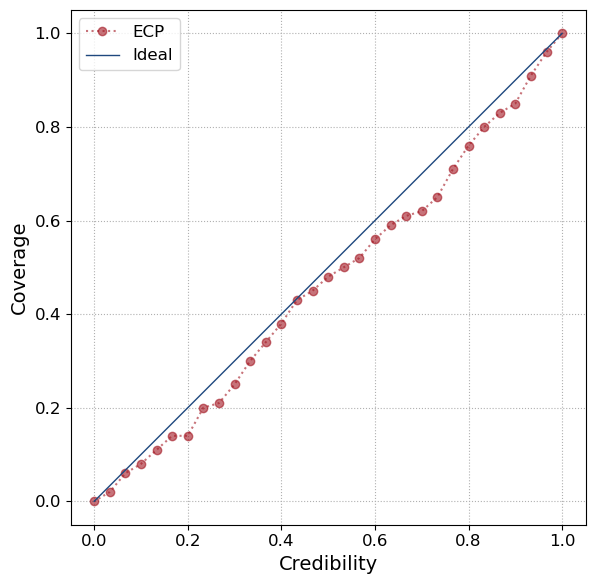

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Credibility', ylabel='Coverage'>)

In [31]:
plt_tools.plot_ecp(alphas, ecp_n, sim_path, file_name="tarp_nre") 

In [32]:
stat, p = kstest(f_n, "uniform")
print(f"NRE p-value : {100*p:.1f} %")

NRE p-value : 40.5 %


## Pull

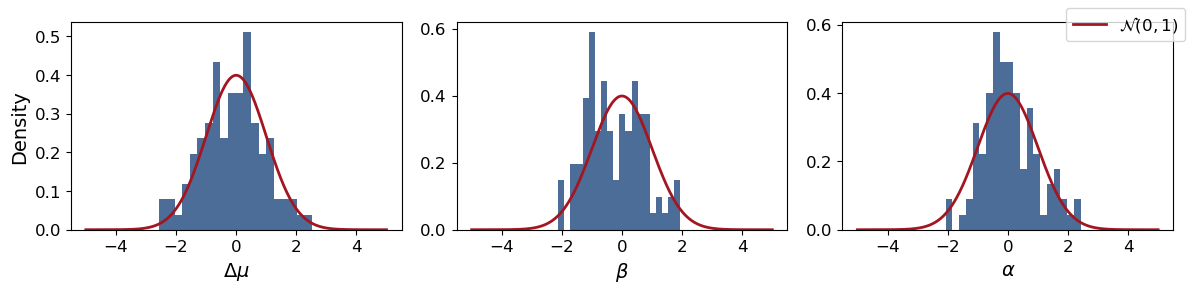

In [33]:
plt_tools.plot_pulls(mu_nn, true_thetas, cov_nn, global_param_names, plt_tools.param_labels, sim_path, file_name="systematics_nre")

# Systematics

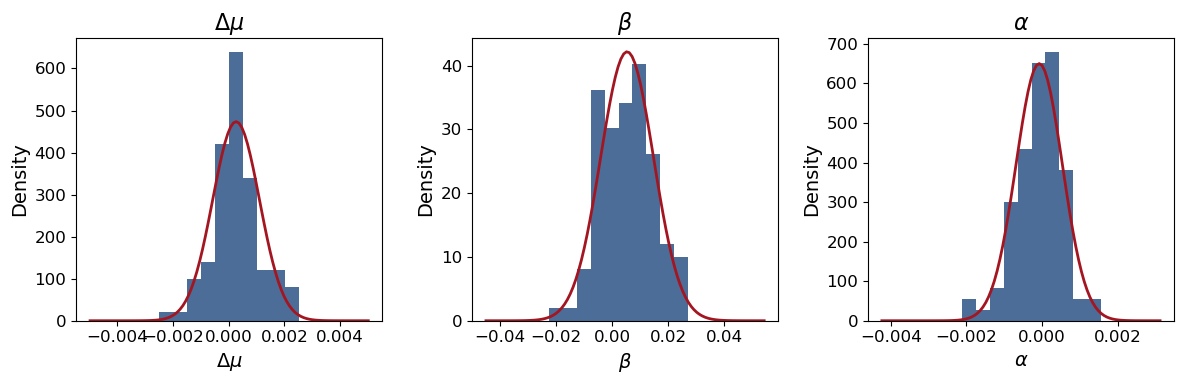

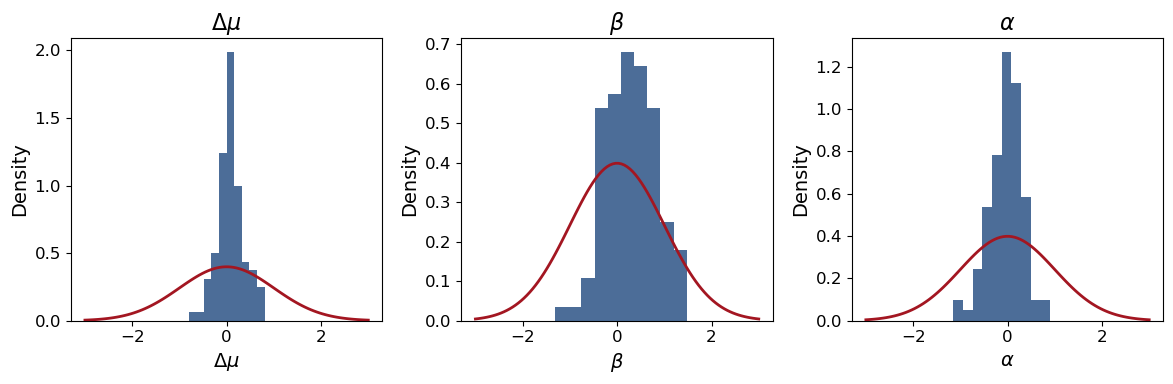

In [72]:
# Fit Gaussian using the empirical mean and standard deviation
plt_tools.plot_bias_histograms(mu_list, mu_nn, names, param_labels)

In [ ]:
# Standardize using the diagonal of the supplied covariance matrix
plt_tools.plot_bias_histograms(mu_list, mu_nn, names, param_labels, cov=cov_list)